# Solar Astronomy

Vier Blicke auf die Aktivität der Sonne, jeweils mit echten Daten: der Sonnenfleckenzyklus seit 1749 mit Glättung, Periodogramm, Kurvenform und einer Prognose für Zyklus 25, rund 20 000 Röntgenflares der GOES-Satelliten von 2017 bis 2026, die Orte der Flares auf der Sonnenscheibe mit Schmetterlingsdiagramm, und der stärkste Flare von Zyklus 25 im Bild des Solar Dynamics Observatory (SDO). Die Daten kommen von SILSO (Sonnenfleckenzahl), NOAA (GOES-Röntgenflüsse, Tagesberichte des Space Weather Prediction Center), SDO über sunpy und der Heliophysics Event Knowledgebase (HEK); Downloads landen in `data/sun/`. Der Code steht in [`code/sun/`](https://github.com/deltorobarba/science/tree/main/code/sun) (`sunspots.py`, `flares.py`, `positions.py`, `sdo.py`, dazu `sundata.py` für die Sonnenfleckenzahl und den Cache von sunpy); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Alle vier Teile folgen derselben Spur: vom Magnetfeld, das der Dynamo im Inneren erzeugt, zu den Ausbrüchen, die an der Erde als Weltraumwetter ankommen. Starke Sonnenstürme stören Satelliten, Funk und GPS und können Stromnetze lahmlegen, wie 1989 in Québec.

- **Schritte 1 bis 8, Zyklus:** Die Zahl der Sonnenflecken steigt und fällt alle elf Jahre, aber unregelmäßig. Länge und Form der Zyklen und wie früh sich ihre Stärke vorhersagen lässt.
- **Schritte 9 bis 15, Flares:** Plötzliche Ausbrüche über Fleckengruppen, gemessen als Röntgenfluss der ganzen Sonne. Ihre Rate folgt dem Zyklus, ihre Größen einem Potenzgesetz.
- **Schritte 16 bis 22, Orte:** Flares entstehen in zwei Gürteln beiderseits des Äquators, die im Lauf eines Zyklus zum Äquator wandern (Schmetterlingsdiagramm), bevorzugt in Regionen mit verwickeltem Magnetfeld.
- **Schritte 23 bis 29, Bild:** Der stärkste Flare von Zyklus 25 im Bild von SDO. Er sitzt genau über der Grenze zwischen den magnetischen Polaritäten, mit zwei hellen Bändern beiderseits, wie es das Standardmodell der Flares verlangt.

Die gemeinsame Lehre: Je näher man hinsieht, von einer Zahl pro Monat über einen Fluss pro Minute bis zum Bild mit Magnetfeld, desto deutlicher wird, dass alle Aktivität aus dem Magnetfeld kommt.

In [1]:
import sys
import subprocess
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "sun"
if "google.colab" in sys.modules:                            # in Colab: Pakete installieren, Code aus dem Repository holen
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sunpy[net,map]", "h5netcdf"], check=True)
    if not CODE.exists():
        CODE.mkdir(parents=True)
        for f in ["sundata.py", "sunspots.py", "flares.py", "positions.py", "sdo.py"]:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/sun/{f}", CODE / f)
elif importlib.util.find_spec("sunpy") is None or not (importlib.util.find_spec("h5netcdf") or importlib.util.find_spec("netCDF4")):
    raise ImportError("Es fehlen sunpy oder ein Leser für NetCDF4 (h5netcdf); lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import sunspots, flares, positions, sdo

**1. Zyklus: die Sonnenfleckenzahl seit 1749**

Die Zahl der Sonnenflecken steigt und fällt mit etwa elf Jahren, und mit ihr fast alle Formen der Sonnenaktivität. Sie ist die längste fortlaufende Messreihe der Astronomie, monatlich seit 1749. SILSO (Royal Observatory of Belgium) liefert die Monatsmittel und eine offizielle 13-Monats-Glättung, nach der die Minima und Maxima der Zyklen festgelegt werden; die neuesten Werte sind vorläufig.

Die Ausgabe gibt 3333 Monatsmittel von Januar 1749 bis September 2026, endgültig bis März 2026; die offizielle Glättung reicht bis März 2026. Das höchste Monatsmittel aller Zeiten, 398.2, stammt vom Mai 1778.

In [2]:
REFRESH = False                # True: Reihen neu von SILSO laden (SILSO ergänzt jeden Monat den Vormonat)
cycle = sunspots.load(REFRESH)

Monatsmittel:  3333 Monate, 1749-01 bis 2026-09 (letzter Wert 60.3)
Endgültig bis: 2026-03; danach vorläufig
Offiziell geglättet bis 2026-03 (94.5)
Höchstes Monatsmittel: 398.2 (1778.37)


**2. Die 13-Monats-Glättung**

Die Glättung mittelt 13 Monate, die beiden äußeren mit halbem Gewicht. Sie wird selbst berechnet und mit der offiziellen Reihe verglichen; dazu kommt ihre Übertragungsfunktion, also welcher Anteil einer Schwingung welcher Periode durchkommt.

Eigene und offizielle Glättung liegen genau aufeinander, höchstens 0.05 auseinander, so viel wie die Rundung der SILSO-Datei. Die Glättung ist ein Tiefpass: Die 11-Jahres-Schwingung behält 98.6 %, eine 2-Jahres-Schwingung 63 %, Perioden von 12, 6, 4 und 3 Monaten verschwinden ganz. Das höchste Monatsmittel (398.2) liegt 40 % über dem höchsten geglätteten Wert (285.0 im Jahr 1958). Man sieht auch die Doppelspitzen der Zyklen 23 und 24.

Eigene minus offizielle Glättung: max |Δ| = 0.050, RMS = 0.029  (SILSO rundet auf 0.1)
Periode 132 Monate: H = +0.986
Periode  60 Monate: H = +0.935
Periode  24 Monate: H = +0.633
Periode  12 Monate: H = +0.000
Periode   6 Monate: H = -0.000
Höchstes Monatsmittel 398.2 gegen höchsten geglätteten Wert 285.0


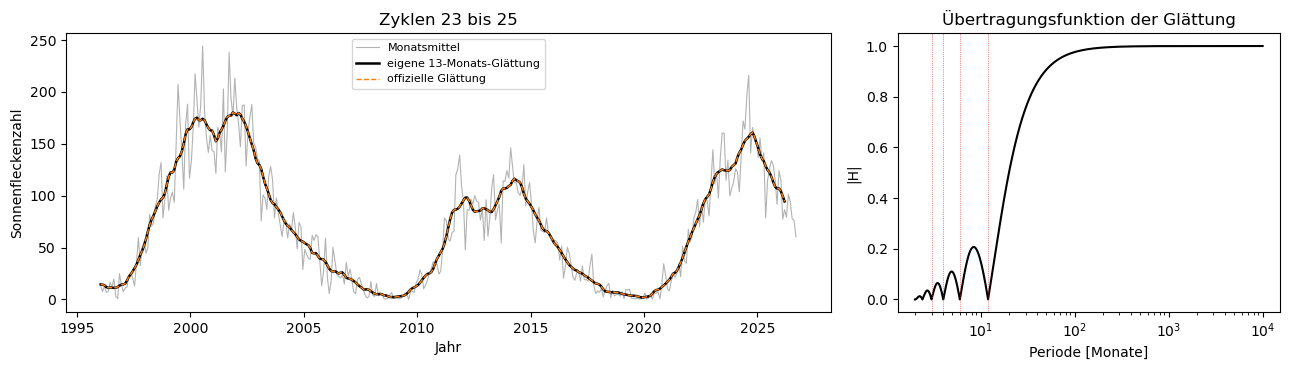

In [3]:
sunspots.smoothing(cycle)

**3. Minima, Maxima und Zykluslängen**

In der Glättung werden Minima und Maxima mit mindestens sieben Jahren Abstand gesucht. Jedes Minimum eröffnet einen Zyklus; seine Länge reicht bis zum nächsten Minimum, sein Anstieg bis zum Maximum.

24 abgeschlossene Zyklen dauern im Mittel 11.03 ± 1.18 Jahre, der kürzeste 9.0 (Zyklus 2), der längste 13.6 Jahre (Zyklus 4). Der Anstieg dauert im Mittel 4.4 Jahre, der Abfall 6.7: Die Zyklen sind schief. Die Höhe schwankt von 81 in den Zyklen 5 und 6 während des Dalton-Minimums bis 285 in Zyklus 19 (1958); Zyklus 24 war mit 116 der schwächste seit über hundert Jahren, Zyklus 25 erreichte 161. Die Minima liegen fast immer nahe null; die Unregelmäßigkeit steckt in Höhe und Länge.

 zyklus   t_min  sn_min   t_max  sn_max  laenge  anstieg  abfall
      1 1755.12   13.99 1761.46  144.12   11.33     6.33    5.00
      2 1766.46   18.59 1769.71  192.98    9.00     3.25    5.75
      3 1775.46   11.98 1778.37  264.25    9.25     2.92    6.34
      4 1784.71   15.90 1788.12  235.28   13.58     3.42   10.16
      5 1798.29    5.27 1805.12   81.99   12.34     6.84    5.50
      6 1810.62    0.00 1816.37   81.16   12.75     5.75    7.00
      7 1823.37    0.15 1829.87  119.24   10.50     6.50    4.00
      8 1833.87   12.20 1837.20  244.87    9.66     3.33    6.33
      9 1843.54   17.62 1848.12  219.94   12.42     4.59    7.83
     10 1855.96    5.99 1860.12  186.15   11.25     4.17    7.08
     11 1867.20    9.88 1870.62  234.02   11.75     3.42    8.34
     12 1878.96    3.74 1883.96  124.41   11.25     5.00    6.25
     13 1890.20    8.28 1894.04  146.55   11.84     3.84    8.00
     14 1902.04    4.48 1906.12  107.08   11.50     4.08    7.41
     15 1913.54    2.45 1

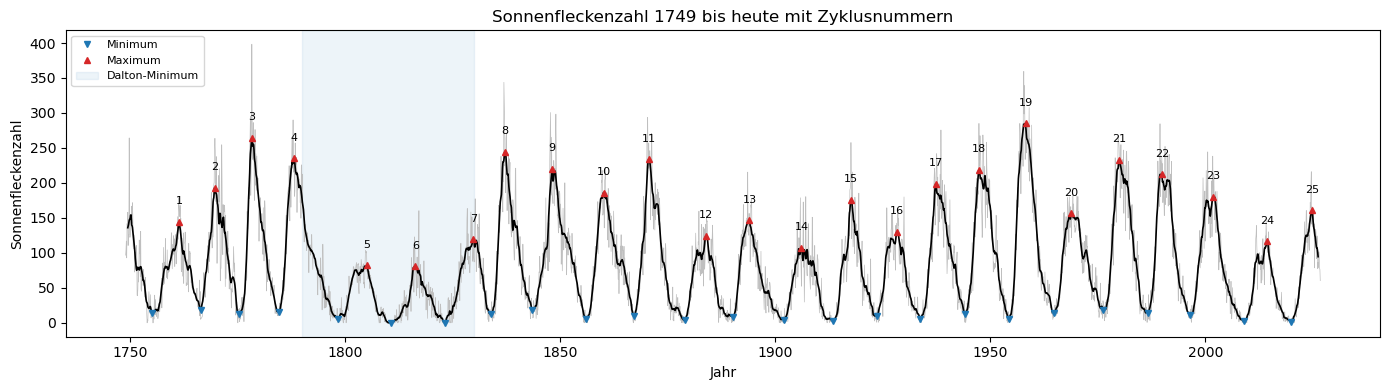

In [4]:
sunspots.extrema(cycle)

**4. Das Periodogramm**

Das Lomb-Scargle-Periodogramm passt für jede Periode zwischen 3 und 150 Jahren eine Sinusschwingung an und misst, wie viel Varianz sie erklärt.

Der höchste Peak liegt bei 11.00 Jahren mit der Leistung 0.24: Ein einziger Sinus erklärt ein Viertel der Varianz. Seine Halbwertsbreite ist 0.65 Jahre, viel schmaler als die Spanne der einzelnen Zykluslängen; das Periodogramm misst die mittlere Periode über 277 Jahre sehr genau, die verschiedenen Längen erscheinen als Nebenpeaks bei 10.0 und 11.8 Jahren. Der breite Buckel um 98 Jahre entspricht dem Gleissberg-Zyklus, aber die Reihe enthält davon nur 2.8 Perioden, zu wenig für einen sicheren Nachweis.

Höchster Peak: P = 11.00 Jahre, Leistung 0.24
Halbwertsbreite des Peaks: 0.65 Jahre; erwartet etwa P²/T = 0.44 Jahre
Mittlere Zykluslänge (Schritt 3): 11.03 Jahre, Streuung ± 1.18
Die sechs höchsten Peaks: 11.0 J (0.24), 10.0 J (0.11), 11.8 J (0.08), 97.8 J (0.07), 8.5 J (0.03), 66.8 J (0.03)


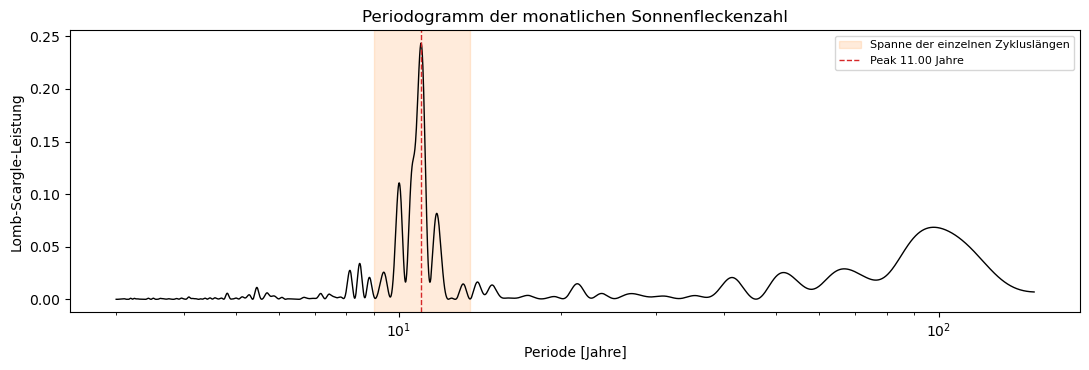

In [5]:
sunspots.periodogram(cycle)

**5. Die Kurvenform jedes Zyklus**

Hathaway, Wilson und Reichmann (1994) beschrieben die Form eines Zyklus mit einer Kurve aus drei Parametern: a für die Höhe, b für die Breite und t₀ für den Beginn. Sie wird an die Monatsmittel jedes Zyklus angepasst.

Die Kurve folgt jedem Zyklus gut, auch den schwachen des Dalton-Minimums und dem laufenden Zyklus 25; bei Doppelspitzen legt sie ihr Maximum dazwischen. Die Breite b liegt bei allen Zyklen zwischen 3.3 und 5.6 Jahren (Mittel 4.35 ± 0.55), die Höhe a schwankt dagegen um den Faktor zehn. Die Monatswerte streuen im Mittel um 25 Flecken um die Kurve, meist durch Schwankungen von Monat zu Monat.

u* = 1.169:  Maximum bei t0 + 1.081·b,  Höhe 0.504·a·b³
 zyklus     a    b      t0  a_err  t_max_fit  A_fit   rms   n
    1.0  1.29 5.63 1754.75   0.17    1760.83 116.08 22.02 136
    2.0  4.75 4.16 1765.69   0.72    1770.19 172.71 35.58 108
    3.0 13.69 3.27 1775.41   1.53    1778.94 240.53 33.62 111
    4.0  3.28 5.05 1783.33   0.29    1788.79 212.51 28.35 163
    5.0  1.70 4.57 1798.56   0.17    1803.50  81.99 12.13 148
    6.0  1.87 4.23 1812.21   0.31    1816.78  71.27 17.04 153
    7.0  2.26 4.67 1823.98   0.32    1829.03 115.94 22.59 126
    8.0  7.73 3.84 1833.44   0.91    1837.59 220.13 34.80 116
    9.0  2.52 5.27 1843.17   0.29    1848.86 185.63 33.20 149
   10.0  3.14 4.77 1855.47   0.30    1860.63 171.78 24.78 135
   11.0  7.39 3.83 1866.93   0.70    1871.08 209.75 27.10 141
   12.0  2.55 4.46 1878.28   0.32    1883.11 114.28 20.89 135
   13.0  3.59 4.25 1889.28   0.35    1893.87 139.12 19.30 142
   14.0  2.06 4.68 1901.41   0.30    1906.47 106.63 23.40 138
   15.0  4.77 

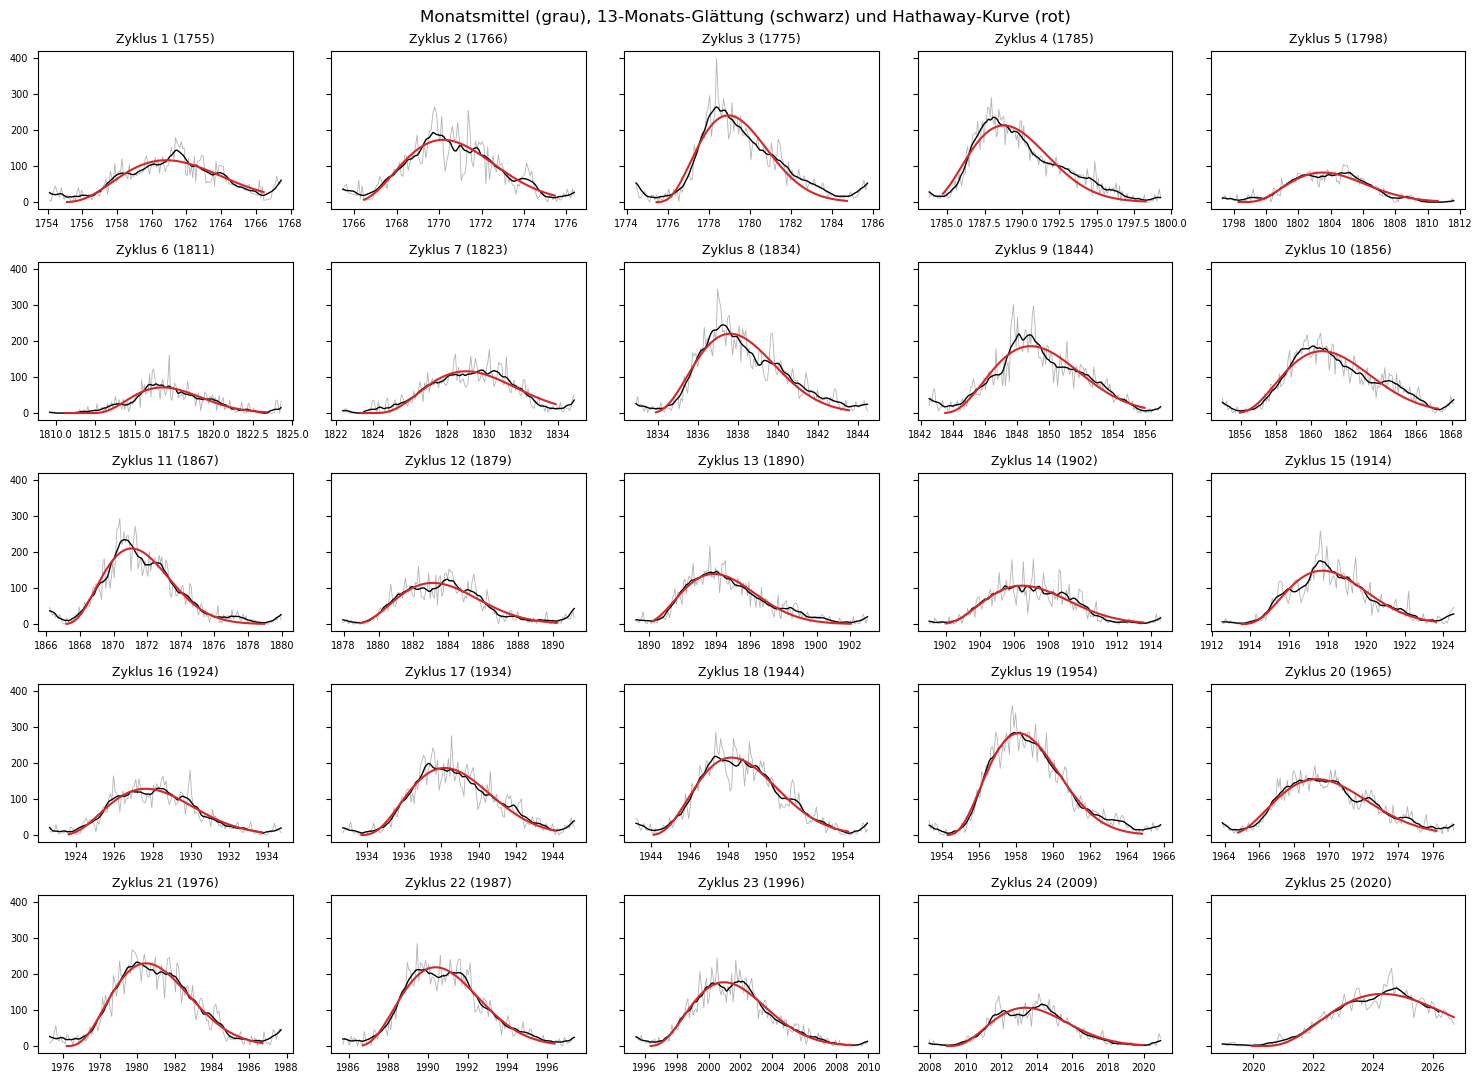

In [6]:
sunspots.shapes(cycle)

**6. Der Waldmeier-Effekt**

Steigen starke Zyklen schneller an? Für die 24 abgeschlossenen Zyklen werden Anstiegszeit und Zykluslänge mit dem Maximum korreliert, und der Zusammenhang wird als Beziehung zwischen den Formparametern a und b gefasst.

Die schwachen Zyklen 5, 6 und 7 brauchten sechs bis sieben Jahre bis zum Maximum, die starken nur rund drei: r = −0.74, p = 3.5·10⁻⁵, kaum zufällig. Länge und Maximum hängen dagegen nur schwach zusammen (r = −0.32, p = 0.12). Rechts dasselbe in den Formparametern: Großes a geht mit kleinem b einher, b = 1.35 + 4.17·a^(−1/4) mit 0.32 Jahren Streuung.

Anstiegszeit gegen Maximum: r = -0.74, p = 3.5e-05  (n = 24)
Zykluslänge gegen Maximum:  r = -0.32, p = 0.12
Zusammenhang b(a) = 1.35 + 4.17·a^(-1/4)  [Jahre], Streuung ± 0.32 Jahre


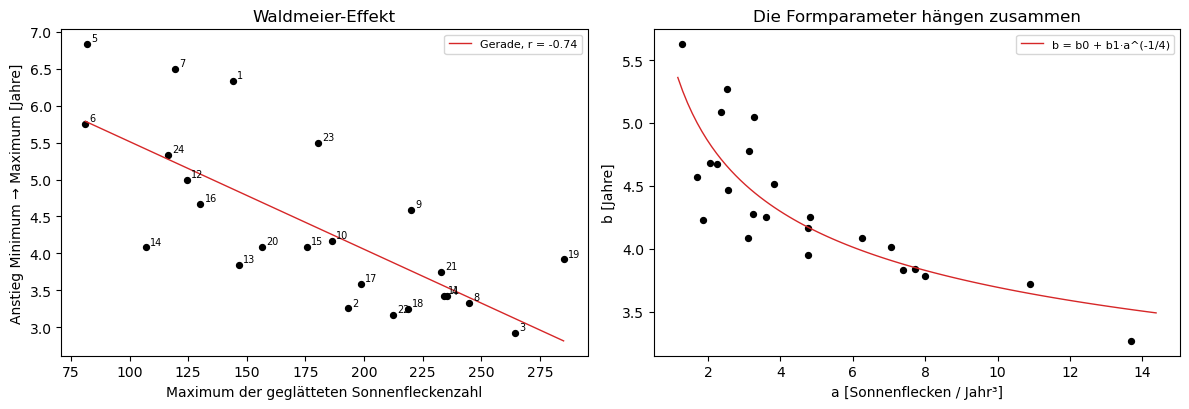

In [7]:
sunspots.waldmeier(cycle)

**7. Prognose für Zyklus 25 aus seinen ersten Jahren**

Mit der Beziehung b(a) aus Schritt 6 hat die Kurve nur noch zwei freie Parameter. Angepasst wird sie an die ersten 1.5, 2, 3 und 4 Jahre nach dem Minimum vom Dezember 2019; die Unsicherheit der Höhe stammt aus 400 Zufallsziehungen der Parameter. Zum Vergleich der Fit an alle Daten und die Vorhersage des NOAA/NASA-Panels von 2019.

Aus 1.5 und 2 Jahren bleiben die Prognosen viel zu niedrig (83 ± 19 und 95 ± 15), aus 3 und 4 Jahren liegen sie nahe am Fit an alle Daten (137 ± 8 und 144 ± 6 gegen 145). Die frühen verfehlen weit außerhalb ihrer Fehler, weil die Streuung von b(a) darin fehlt. Beobachtet wurde ein geglättetes Maximum von 160.9 im Oktober 2024; ab drei Jahren liegt die Prognose innerhalb von 15 %.

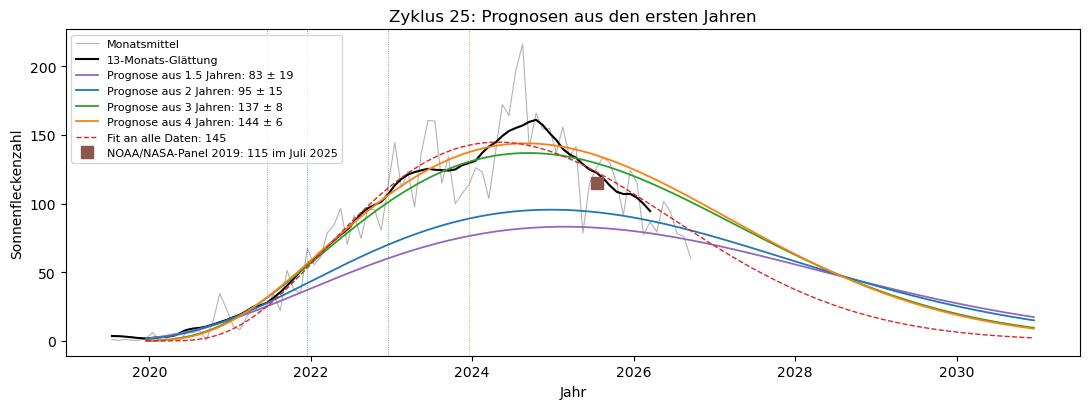

 jahre    a      t0  maximum  fehler  zeitpunkt
   1.5 0.96 2019.13    83.11   18.98    2025.14
   2.0 1.32 2019.31    95.50   14.97    2024.97
   3.0 2.89 2019.78   136.77    7.80    2024.70
   4.0 3.21 2019.84   143.79    5.59    2024.66

Beobachtet (geglättet): Maximum 160.9 bei 2024.79;  Fit an alle Daten: 144.7 bei 2024.32


In [8]:
YEARS = (1.5, 2, 3, 4)         # Jahre nach dem Minimum, die die Prognose kennt
sunspots.forecast(cycle, YEARS)

**8. Vergleich mit der offiziellen Reihe und dem Panel von 2019**

Dieselbe Suche nach Extrema läuft auf der offiziellen Glättung. Für Zyklus 25 stehen die Vorhersage des Panels, die eigenen Prognosen und das beobachtete Maximum nebeneinander.

Eigene und offizielle Reihe haben dieselben 25 Minima und 25 Maxima; die Maxima fallen in dieselben Monate, vier Minima liegen bis zu drei Monate auseinander, weil die Reihe dort so flach ist, dass die Rundung den Monat entscheidet. Das Panel sagte 115 im Juli 2025 voraus; beobachtet wurden 160.9 im Oktober 2024, 40 % mehr und neun Monate früher. Die eigenen Prognosen aus 3 und 4 Jahren lagen näher, waren aber erst möglich, als der Anstieg schon zur Hälfte vorbei war.

In [9]:
sunspots.compare(cycle)

Offizielle Reihe: 25 Minima, 25 Maxima;  eigene: 25 Minima, 25 Maxima
Größte Abweichung der Daten: Minima 3 Monate, Maxima 0 Monate
  Minimum vor Zyklus 6: eigene 1810.62 (0.00), offiziell 1810.54 (0.0)
  Minimum vor Zyklus 7: eigene 1823.37 (0.15), offiziell 1823.29 (0.2)
  Minimum vor Zyklus 16: eigene 1923.62 (9.35), offiziell 1923.54 (9.4)
  Minimum vor Zyklus 23: eigene 1996.37 (11.17), offiziell 1996.62 (11.2)

Zyklus 25
                                       Maximum   Zeitpunkt
NOAA/NASA-Panel (Dezember 2019)            115     2025.54   (Spanne 105-125, ± 8 Monate)
eigene Prognose aus 1.5 Jahren              83     2025.14
eigene Prognose aus 2.0 Jahren              95     2024.97
eigene Prognose aus 3.0 Jahren             137     2024.70
eigene Prognose aus 4.0 Jahren             144     2024.66
eigener Fit an alle Daten                  145     2024.32
offizielle Glättung (beobachtet)         160.9     2024.79


**9. Flares: zwei Listen der GOES-Satelliten**

Ein Flare setzt über einer Fleckengruppe in wenigen Minuten bis zu 10²⁵ J frei. Sein Röntgenlicht erreicht die Erde nach acht Minuten, ionisiert die obere Atmosphäre und unterbricht den Kurzwellenfunk. Seit 1975 messen die geostationären GOES-Satelliten der NOAA den Röntgenfluss der ganzen Sonne; die Klasse eines Flares (A, B, C, M, X, je zehnmal stärker) folgt aus dem Spitzenfluss. Geladen werden die Flare-Listen von GOES-16 und GOES-18 in wissenschaftlicher Qualität und die Sonnenfleckenzahl.

GOES-16 hat von Februar 2017 bis April 2025 16 085 Flares, GOES-18 von Juni 2022 bis Oktober 2026 13 660. Fast alle sind Klasse B oder C; GOES-16 hat mehr B-Flares (4780 gegen 942), weil es die ruhigen Jahre 2018 bis 2020 sah, als der Hintergrund niedrig war.

In [10]:
EVENT_DAY = "2024-10-03"       # Tag des X-Flares für die Lichtkurve (Schritt 14)
fla = flares.load(EVENT_DAY, REFRESH)

GOES-16: 2017-02-09 bis 2025-04-06, 16085 Flares  A: 2  B: 4780  C: 9612  M: 1609  X: 82   (Datei sci_xrsf-l2-flsum_g16_s20170209_e20250406_v2-2-1.nc)
GOES-18: 2022-06-17 bis 2026-10-11, 13660 Flares  A: 0  B: 942  C: 10806  M: 1819  X: 93   (Datei sci_xrsf-l2-flsum_g18_s20220617_e20261011_v2-2-1.nc)


**10. Aus Ereignissen werden Flares**

Die Liste hat für jeden Flare mehrere Zeilen: Start, Maximum, Ende. Zu jedem Maximum werden Start und Ende gesucht; daraus folgen Anstieg, Abfall und der Spitzenfluss ohne Hintergrund. Die Klasse wird selbst nachgerechnet, einmal mit abgeschnittener und einmal mit gerundeter Mantisse. Eine gemeinsame Reihe nimmt GOES-16 bis zu seinem letzten Tag, danach GOES-18.

Abgeschnitten stimmt die eigene Klasse bei 100 % mit der Liste überein, gerundet nur bei der Hälfte. Die gemeinsame Reihe hat 20 651 Flares. An der Spitze stehen X14.6 und X12.9 vom September 2017; damals gemeldet wurden X9.3 und X8.2, weil NOAA die Flüsse bis 2020 mit 0.7 multiplizierte; der Rest von etwa 10 % ist Kalibrierung. Der stärkste Flare von Zyklus 25 ist der vom 3. Oktober 2024 mit X8.9 bei GOES-16.

In [11]:
flares.classes(fla)

GOES-16: eigene Klasse = Listenklasse bei 100.0% (abgeschnitten) bzw. 50.5% (gerundet); 13% ohne Ende (nächster Flare begann vorher)
GOES-18: eigene Klasse = Listenklasse bei 100.0% (abgeschnitten) bzw. 50.4% (gerundet); 13% ohne Ende (nächster Flare begann vorher)

Gemeinsame Reihe: 20651 Flares von 2017-02 bis 2026-10 (GOES-16 bis 2025-04-06, danach GOES-18)

Die zehn stärksten Flares:
             t_peak klasse  anstieg  abfall           bg  sat
2017-09-06 12:02:00  X14.6     10.0     8.0 8.114693e-06   16
2017-09-10 16:06:00  X12.9     32.0    25.0 6.477831e-07   16
2024-10-03 12:18:00   X8.9     10.0     8.0 9.305923e-06   16
2024-05-14 16:51:00   X8.6      5.0    10.0 5.033336e-06   16
2026-02-01 23:57:00   X8.1     13.0     7.0 1.042265e-05   18
2024-10-01 22:20:00   X7.0     22.0     8.0 6.726740e-06   16
2024-05-11 01:23:00   X5.8     13.0    15.0 1.001130e-05   16
2025-11-11 10:04:00   X5.1     15.0    13.0 2.835215e-06   18
2023-12-31 21:55:00   X4.9     19.0    12.0 1.89226

**11. Flare-Rate und Sonnenfleckenzahl**

Für jeden vollständigen Monat werden die Flares ab C1, ab M1 und ab X1 gezählt und mit der Sonnenfleckenzahl R verglichen; für die M-Flares mit einer Poisson-Regression N = k·R^β.

Alle Raten folgen dem Zyklus: fast keine Flares im Minimum 2018 bis 2020, die meisten 2024. Die Rangkorrelation ist 0.93 für C-, 0.90 für M- und nur 0.61 für X-Flares, die selten sind und in Schüben kommen. Die M-Flares wachsen wie R^1.77: doppelt so viele Flecken, mehr als dreimal so viele M-Flares. Die Monatszahlen schwanken aber 32-mal so stark wie bei einem Poisson-Prozess. 2019 gab es bei R = 4 nur 3 M-Flares, 2024 bei R = 155 864 M- und 50 X-Flares.

108 Monate von 2017-03 bis 2026-09
≥C1 gegen Sonnenfleckenzahl: Spearman ρ = 0.93
≥M1 gegen Sonnenfleckenzahl: Spearman ρ = 0.90
≥X1 gegen Sonnenfleckenzahl: Spearman ρ = 0.61
M-Flares pro Monat = 0.0075 · R^1.77 (± 0.01 unter Poisson-Annahme)
χ²/dof = 31.6: die Varianz ist 32-mal so groß wie bei Poisson; realistischer Fehler von β ≈ ± 0.04

Flares pro Jahr:
t_peak   2017  2018  2019  2020   2021    2022    2023    2024    2025    2026
C       413.0  33.0  64.0  83.0  443.0  2192.0  2845.0  2794.0  2654.0  1566.0
M        53.0   1.0   3.0   2.0   29.0   193.0   351.0   864.0   332.0   213.0
X         6.0   0.0   0.0   0.0    1.0     7.0    13.0    50.0    18.0    13.0
SN       22.0   7.0   4.0   9.0   29.0    83.0   125.0   155.0   123.0    85.0


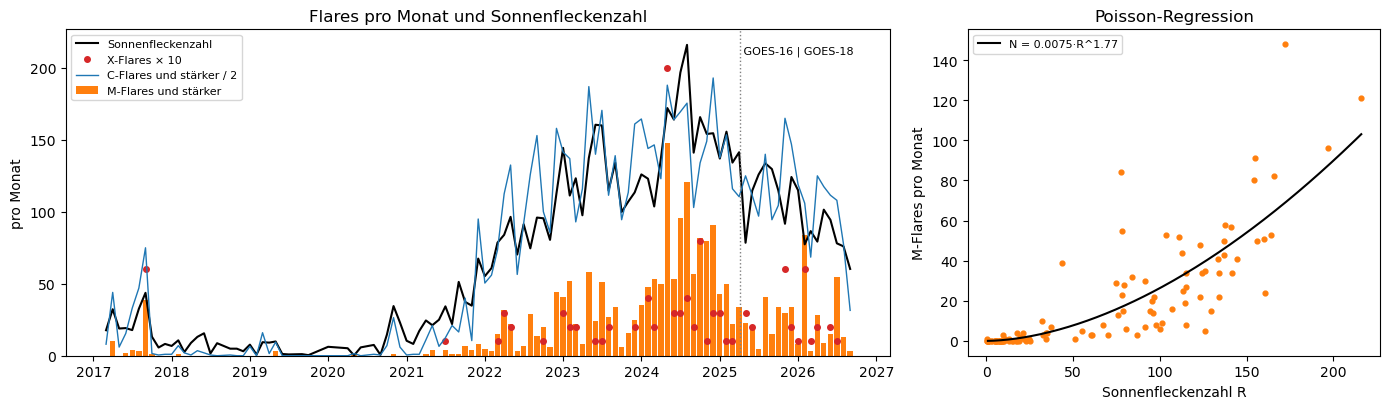

In [12]:
flares.rate(fla)

**12. Die Verteilung der Spitzenflüsse**

Die Spitzenflüsse folgen einem Potenzgesetz, wenige große und sehr viele kleine Flares. Für 41 Schwellen wird der Exponent mit Maximum Likelihood geschätzt und mit dem Kolmogorov-Smirnov-Abstand geprüft, ab welcher Schwelle die Liste vollständig ist; einmal mit und einmal ohne Hintergrund.

Unterhalb von etwa C1 fehlen Flares, darüber fällt die Verteilung fast gerade ab, über X1 etwas schneller. Der Exponent ist 2.27 ± 0.02 mit Hintergrund (ab C6.3) und 2.06 ± 0.02 ohne (ab C5.6). Mit Hintergrund ist das Gesetz steiler, weil der Hintergrund kleine Flares über die Schwelle hebt; er stieg von A9 (2018) auf C2.6 (2024), und 95 % der Flares von 2024 begannen über C1.

Spitzenfluss F         F_min = 6.3e-06 W/m² (C6.3),  α = 2.268 ± 0.020,  n = 3830,  D = 0.012
ohne Hintergrund ΔF    F_min = 5.6e-06 W/m² (C5.6),  α = 2.061 ± 0.021,  n = 2477,  D = 0.017

Hintergrund am Flarestart (Median) und Anteil über C1:
t_peak      2017    2018    2019    2020    2021    2022    2023    2024    2025    2026
median   2.2e-07 9.2e-08 1.3e-07 1.7e-07 1.8e-07 8.8e-07 1.6e-06 2.6e-06 1.5e-06 9.5e-07
ueber_C1    0.13    0.00    0.01    0.01    0.05    0.44    0.81    0.95    0.77    0.47


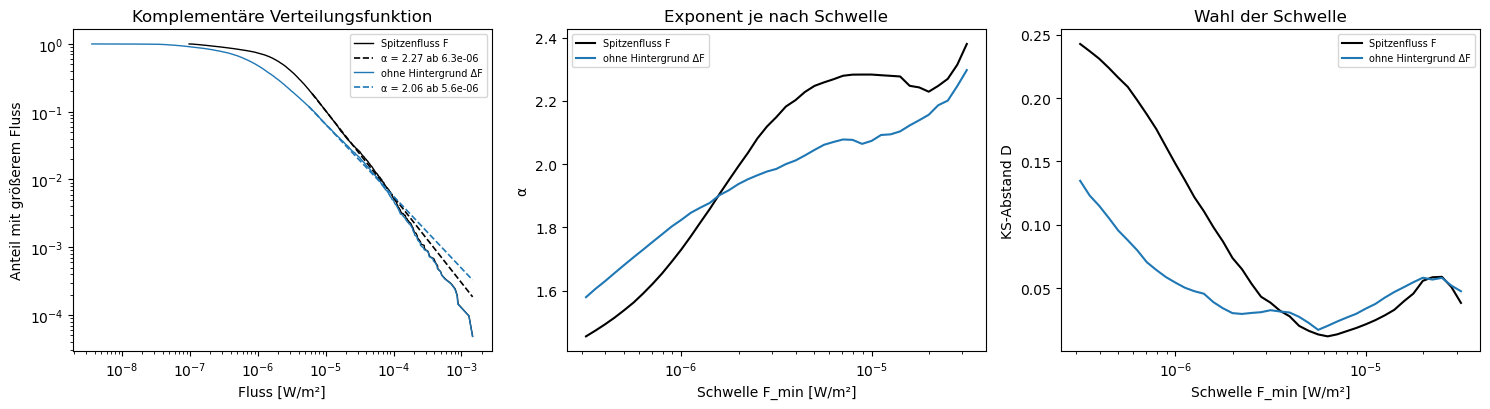

In [13]:
flares.powerlaw(fla)

**13. Anstieg und Dauer**

Für jede Klasse von B bis X werden Anstieg (Start bis Maximum) und Abfall (Maximum bis halbe Höhe) verglichen.

Der Median des Anstiegs wächst von 8 Minuten (B, C) auf 11 (M) und 15 (X), der des Abfalls von 5 auf 9 Minuten; die Streuung ist aber groß, und die Rangkorrelation mit dem Fluss nur 0.21 und 0.14. Die Dauer hängt mehr von der Geometrie der magnetischen Schleifen ab als von der Stärke. Nur 25 % der Flares steigen schneller an, als sie auf die halbe Höhe abfallen, weil der Anstieg ab dem Start zählt, wo der Fluss kaum über dem Hintergrund liegt.

Median in Minuten (Abfall = Maximum bis Hälfte über dem Hintergrund):
   anstieg  abfall      n
F                        
B      8.0     5.0   5413
C      8.0     6.0  13087
M     11.0     8.0   2041
X     15.0     9.0    108

Spearman: log F gegen Anstieg ρ = 0.21, gegen Abfall ρ = 0.14
Anteil der Flares, die schneller ansteigen als abfallen: 25%


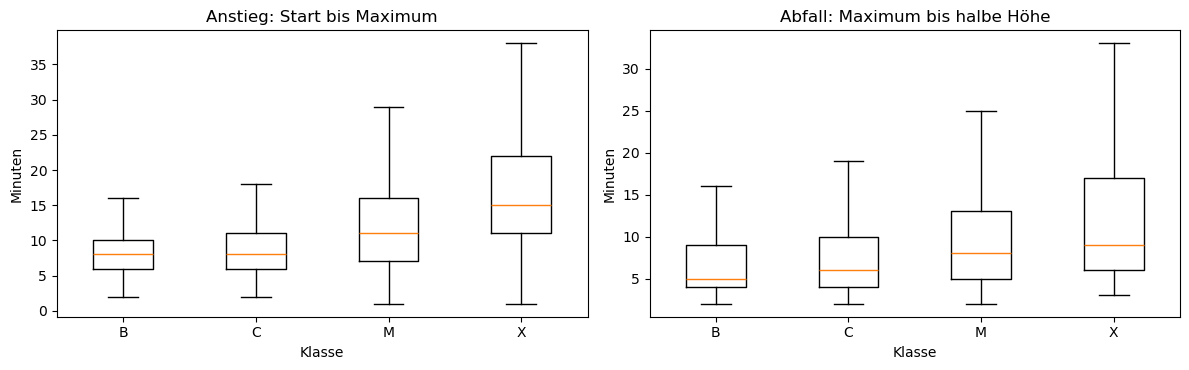

In [14]:
flares.timing(fla)

**14. Die Lichtkurve des X-Flares vom 3. Oktober 2024**

Die 1-Minuten-Werte von GOES-18 zwischen 11:30 und 14:00 UT, beide Kanäle. An die erste Stunde nach dem Maximum wird ein exponentielles Abklingen angepasst. Das Verhältnis der beiden Kanäle (härteres zu weicherem Röntgenlicht) zeigt die Temperatur.

Ab 12:13 UT steigt der Fluss in fünf Minuten um zwei Größenordnungen auf X8.8 (8.806·10⁻⁴ W/m² um 12:18 UT, genau wie in der Liste) und fällt dann mit τ = 7.6 ± 0.1 Minuten ab; die Kurve passt auf 5 %. Die halbe Höhe kommt aber erst nach 8 statt 5.2 Minuten, weil direkt nach dem Maximum noch geheizt wird. Das Härteverhältnis erreicht sein Maximum um 12:16, zwei Minuten vor dem Fluss: Das Plasma ist zuerst am heißesten und erst danach am dichtesten.

Eigenes Maximum: 12:18 UT, F = 8.806e-04 W/m² → X8.8
Flare-Liste GOES-18: Start 12:08, Maximum 12:18, Ende 12:26, Klasse X8.8, Hintergrund 9.2e-06
Abklingzeit τ = 7.6 ± 0.1 min, Hintergrund danach 1.4e-05 W/m², relative Abweichung 5.0%
Halbe Höhe: nach Modell τ·ln2 = 5.2 min, gemessen 8 min (Liste: Ende nach 8 min)
Härteverhältnis A/B: Maximum 0.42 um 12:16, am Flare-Maximum 0.38
Steilster Anstieg von XRS-B um 12:17, 1 min vor dem Maximum


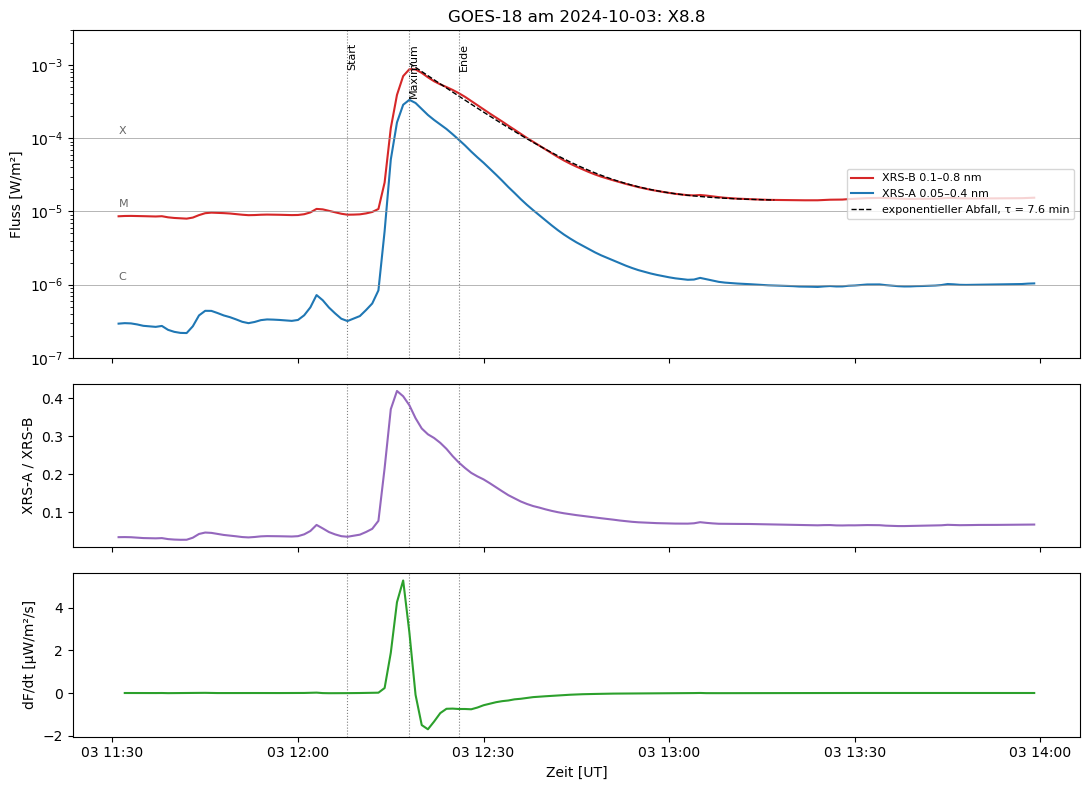

In [15]:
flares.lightcurve(fla)

**15. GOES-16 gegen GOES-18 und gegen die Echtzeitmeldung**

Von Juni 2022 bis April 2025 haben beide Satelliten dieselbe Sonne beobachtet. Die Flares beider Listen werden über ihre Maxima zugeordnet; für Flares, die nur GOES-18 hat, zeigen die Datenmarken von GOES-16 den Grund.

8821 Flares stehen in beiden Listen; GOES-18 misst im Median 0.5 % weniger, und trotzdem stimmt die Klasse nur bei 70 %, weil das Abschneiden schon bei 4.99 gegen 5.01 eine andere Zahl ergibt. 26 M- und X-Flares hat nur GOES-18: 11 fielen in den Erdschatten von GOES-16, 14 in Zeiten schlechter Daten (darunter X6.3 vom 22. Februar 2024), nur einer wurde nicht erkannt. Für den 3. Oktober 2024 ergeben sich X8.8, X8.9 und X9.0 (Echtzeit), 0.6 bis 2.2 % auseinander. Der Exponent 2.06 liegt nahe an 1.98 aus 37 Jahren GOES (Aschwanden und Freeland 2012).

Überlappung 2022-06-17 bis 2025-04-06: GOES-18 9094 Flares, GOES-16 9716; 8821 gemeinsam (Maximum höchstens 3 min auseinander)
Spitzenfluss GOES-18 / GOES-16: Median 0.9949, mittlere 50 % 0.9916 bis 1.0010
Gleiche Klasse bei 70% der gemeinsamen Flares

M- und X-Flares nur bei GOES-18: 26


                                 n  stärkster                                stunden_UT
grund                                                                                  
Daten gut, Flare nicht erkannt   1   0.000014                                       [1]
Erdschatten (Finsternis)        11   0.000041                                    [4, 5]
schlechte oder fehlende Daten   14   0.000634  [0, 2, 5, 8, 10, 12, 16, 20, 21, 22, 23]
Stärkster: X6.3 am 2024-02-22 22:34 – schlechte oder fehlende Daten

Quelle                                        Fluss [W/m²]  Klasse
eigene Klasse aus den Minutenwerten (GOES-18)     8.806e-04    X8.8
Flare-Liste GOES-18                              8.806e-04    X8.8
Flare-Liste GOES-16                              8.943e-04    X8.9
NOAA SWPC Echtzeit (auch in HEK)                 9.000e-04    X9.0

Exponent der Spitzenflüsse ohne Hintergrund: α = 2.06 ± 0.02; Aschwanden & Freeland (2012), 37 Jahre GOES: α ≈ 1.98


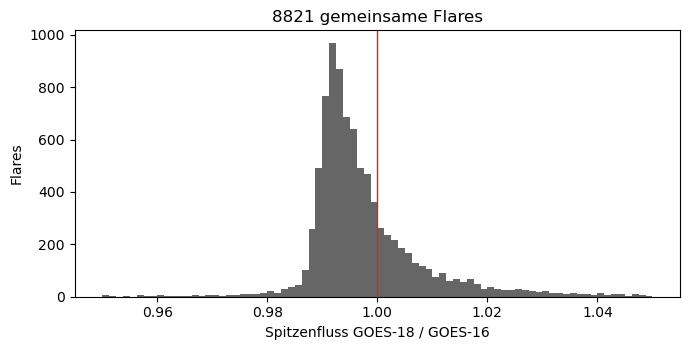

In [16]:
flares.compare(fla)

**16. Orte: Tagesberichte des Space Weather Prediction Center**

Flares entstehen über aktiven Regionen, Fleckengruppen mit starkem Magnetfeld. Das Space Weather Prediction Center der NOAA veröffentlicht täglich zwei Listen: die Ereignisse des Tages, darunter Röntgenflares mit ihrer Region, und die Solar Region Summary (SRS) mit Position, Fläche und magnetischer Klasse jeder Region um 00 UT. Geladen werden beide für jeden Tag von 2024 und jede siebte SRS seit 2016.

Für 2024 sind alle 366 Ereignislisten und 365 SRS im Archiv, mit 3766 Röntgenflares, 3801 Hα-Beobachtungen und 3102 Regionstagen von 412 Regionen. Für das Schmetterlingsdiagramm kommen 436 SRS bis November 2026 mit 1530 Regionen dazu.

In [17]:
YEAR = 2024                    # Jahr für die Flare-Positionen
BUTTERFLY_START = "2016-01-01"  # Beginn des Schmetterlingsdiagramms (jede siebte SRS)
pos = positions.load(YEAR, BUTTERFLY_START)

2024: 366 Ereignislisten, 365 SRS (von 366 Tagen)
Ereignisse nach Typ: {'RSP': 4355, 'FLA': 3801, 'XRA': 3766, 'RBR': 3766, 'DSF': 95, 'RNS': 76}
SRS 2024: 3102 Regionstage, 412 Regionen
Schmetterlingsdiagramm: 436 SRS von 2016-01-01 bis 2026-11-06, 1530 Regionen


**17. Röntgenflares und Regionen**

Aus den Ereignissen vom Typ XRA werden Klasse, Spitzenfluss, Zeit des Maximums und Region gelesen. Die Listen geben die Regionsnummer nur vierstellig; seit 2002 zählt NOAA über 10 000.

Das Jahr 2024 hat 3766 Röntgenflares: 2794 C, 883 M und 54 X, zu 95 % von GOES-16 gemessen; die Echtzeitklassen liegen etwas höher als in den nachbearbeiteten Listen. Bei 8.6 % fehlt die Region, bei M- und X-Flares nur bei 4.5 %. Die zehn stärksten kommen aus sieben Regionen; NOAA 13664 im Mai erzeugte drei, NOAA 13842 im Oktober zwei, darunter den stärksten.

In [18]:
positions.xray(pos)

3766 Röntgenflares: B 35, C 2794, M 883, X 54
Ohne Regionsangabe: 8.6% (Klasse M und X: 4.5%)
Davon von GOES-16: 95%, GOES-18: 5%

Die zehn stärksten Flares:
              t_max klasse  noaa
2024-10-03 12:18:00   X9.0 13842
2024-05-14 16:51:00   X8.7 13664
2024-10-01 22:20:00   X7.1 13842
2024-02-22 22:34:00   X6.3 13590
2024-05-11 01:23:00   X5.8 13664
2024-05-06 06:35:00   X4.5 13663
2024-09-14 15:29:00   X4.5 13825
2024-05-10 06:54:00   X3.9 13664
2024-02-09 13:14:00   X3.3 13575
2024-10-24 03:57:00   X3.3 13869


**18. Die Position jedes Flares**

Zu jedem Flare wird seine Region in der SRS desselben Tages gesucht und ihre Länge mit der differentiellen Rotation auf die Zeit des Maximums gedreht: Die Sonne dreht sich am Äquator in etwa 25 Tagen, an den Polen langsamer. Mit der Neigung der Sonnenachse und dem scheinbaren Sonnenradius zur Flarezeit folgen die Bildkoordinaten.

89.7 % der Flares bekommen eine Position. 118 liegen danach hinter dem Rand, 115 davon am Westrand: Die Region war schon verschwunden, die hohen Schleifen darüber noch sichtbar. Auf der Scheibe liegen die Flares auf waagrechten Spuren, Regionen, die mit der Rotation über die Scheibe wandern, in zwei Bändern nördlich und südlich des Äquators. Der stärkste Flare zeigt die Drehung: Seine Region stand um 00 UT bei S15E06 und hatte sich bis 12:18 UT um 6.9° auf S15W01 gedreht.

quelle
SRS desselben Tages        3095
keine Region                325
SRS des Folgetags           259
Region nicht in der SRS      63
SRS des Vortags              24



Position bestimmt für 89.7% der Flares; davon hinter dem Rand (z < 0): 118, davon 115 am Westrand (Region schon hinter dem Rand, Flare noch sichtbar)
Stärkster Flare X9.0 am 2024-10-03 12:18 in NOAA 13842: SRS S15E06 um 00 UT → gedreht S15W01 (+6.9°), Tx = 15″, Ty = -353″


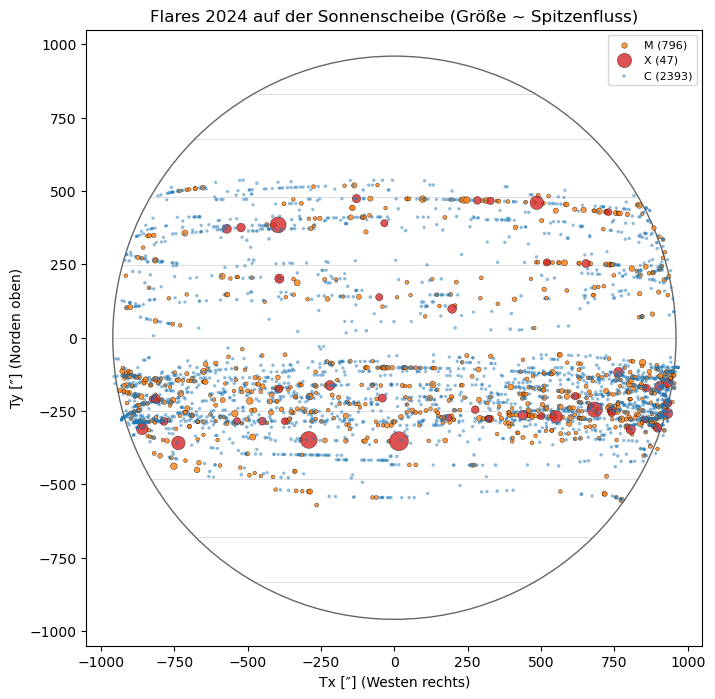

In [19]:
positions.locate(pos)

**19. Die aktiven Breiten**

Für Flares ab C1, ab M1 und für X-Flares werden Breite und Nord-Süd-Asymmetrie gezählt, zum Vergleich die Breiten aller Regionen bei ihrer ersten Sichtung.

Alle liegen in zwei Bändern zwischen etwa 5° und 30° Breite mit einer Lücke um den Äquator; die Hälfte der Flares liegt zwischen 9° und 18°. 2024 war der Süden viel aktiver: 680 der 871 M- und X-Flares kamen von der Südhalbkugel, eine Asymmetrie von −0.56 ± 0.03, bei den Regionen nur 242 zu 170. Einige große, komplexe Regionen im Süden, vor allem NOAA 13664, erzeugten den Überschuss.

C und stärker  n = 3354: |Breite| Median 14.0°, mittlere 50 % 9°–18°;  Nord 854, Süd 2500, Asymmetrie -0.49 ± 0.02
M und stärker  n =  871: |Breite| Median 14.0°, mittlere 50 % 10°–18°;  Nord 191, Süd 680, Asymmetrie -0.56 ± 0.03
X              n =   51: |Breite| Median 17.0°, mittlere 50 % 13°–19°;  Nord 14, Süd 37, Asymmetrie -0.45 ± 0.12
Regionen 2024 (erste Sichtung): |Breite| Median 14.0°, Nord 170, Süd 242


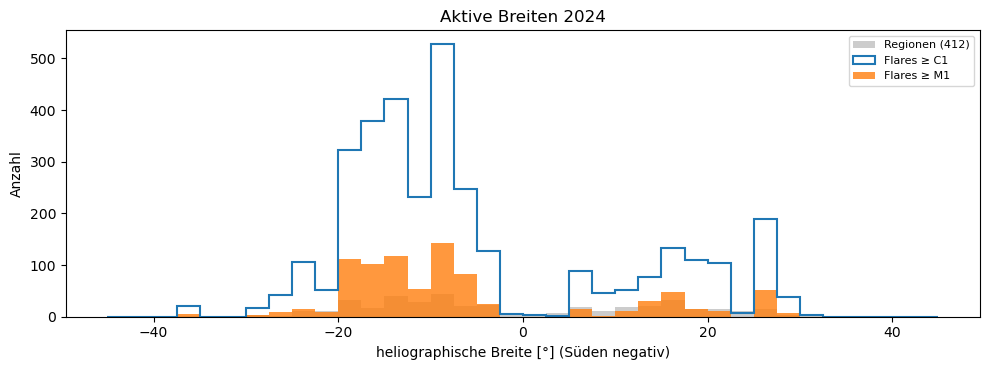

In [20]:
positions.latitudes(pos)

**20. Flares aus δ-Regionen**

In einer δ-Region liegen Flecken entgegengesetzter Polarität so eng beieinander, dass sie sich einen Halbschatten teilen; das Magnetfeld ist dort stark verdreht. Gezählt wird, wie viele Flares aus solchen Regionen kommen, und welche Regionen die produktivsten waren.

Nur 9.1 % der Regionstage hatten eine δ-Konfiguration, aber 32 % der C-, 47 % der M- und 73 % der X-Flares kamen daraus; die Anreicherung wächst mit der Stärke von 3.5 über 5.1 auf 8.0. Angeführt wird die Rangliste von NOAA 13664 mit 64 M- und X-Flares im Mai 2024, darunter 12 X-Flares; sie löste den großen geomagnetischen Sturm vom 10. und 11. Mai 2024 aus. Die zehn produktivsten von 138 Regionen erzeugten 36 % der M- und X-Flares.

In [21]:
positions.delta(pos)

Anteil der Regionstage mit δ-Klasse: 9.1%  (3102 Regionstage)

Klasse    Flares    aus δ-Regionen   Anreicherung
C           2483         32% ± 1%          3.5×
M            820         47% ± 2%          5.1×
X             51         73% ± 6%          8.0×

Die produktivsten Regionen (Fläche in Millionstel der Halbkugel):
       M_und_X   X staerkster     erster lat  max_flaeche  delta_tage  tage
noaa                                                                       
13664       64  12       X8.7 2024-05-02 -19       2400.0        10.0  13.0
13615       42   1       X1.1 2024-03-18 -13       1140.0        11.0  13.0
13663       40   5       X4.5 2024-05-01 +26        600.0         6.0  11.0
13697       34   6       X2.8 2024-05-27 -18        420.0        13.0  14.0
13842       31   4       X9.0 2024-09-29 -14       1040.0         8.0  12.0
13576       24   1       X2.5 2024-02-04 -16        740.0        11.0  13.0
13883       22   1       X2.3 2024-11-03  -6        420.0         7.

**21. Schmetterlingsdiagramm und Wanderung der Fleckenzonen**

Für jede Region zählt die Breite bei ihrer ersten Sichtung. Im Lauf eines Zyklus erscheinen neue Regionen immer näher am Äquator; an die Regionen von Zyklus 25 wird ein exponentielles Gesetz angepasst, die Breite fällt von φ₀ mit der Zeitskala τ ab dem Minimum im Dezember 2019.

Nach dem Minimum erscheinen die Regionen von Zyklus 25 plötzlich bei 20° bis 30° Breite und rücken dann langsam zum Äquator: φ₀ = 24.5 ± 0.7°, τ = 9.0 ± 0.6 Jahre, im Norden (23.9°, 9.6 Jahre) und Süden (25.1°, 8.4 Jahre) innerhalb der Fehler gleich. 2019 lagen 91 % der neuen Regionen unter 10° Breite, 2020 lag die mittlere Breite plötzlich bei 21°, seitdem sank sie auf 12.6° im Jahr 2026.

beide  n = 1342: φ0 = 24.5 ± 0.7°,  τ = 9.0 ± 0.6 Jahre
Nord   n =  650: φ0 = 23.9 ± 1.1°,  τ = 9.6 ± 1.0 Jahre
Süd    n =  692: φ0 = 25.1 ± 1.0°,  τ = 8.4 ± 0.7 Jahre

Mittlere |Breite| neuer Regionen pro Jahr:
tag        2016   2017   2018   2019   2020   2021    2022    2023    2024    2025    2026
n         98.00  50.00  21.00  11.00  26.00  88.00  191.00  272.00  312.00  281.00  180.00
mittel    10.72  10.94   8.62   8.36  20.65  20.42   19.27   16.29   14.34   13.05   12.58
unter_10   0.47   0.38   0.67   0.91   0.08   0.00    0.06    0.15    0.27    0.33    0.34


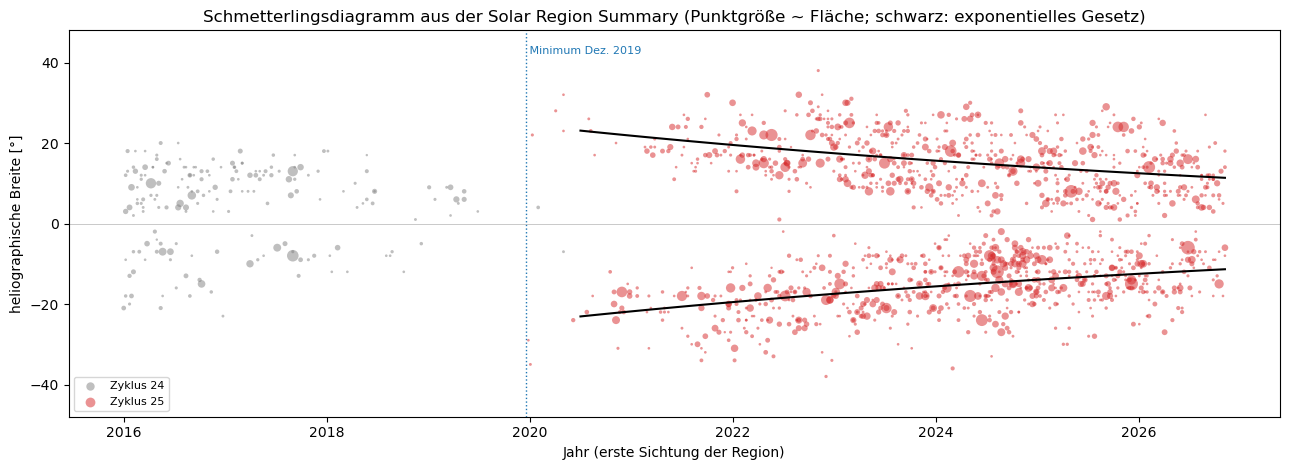

In [22]:
positions.butterfly(pos)

**22. Vergleich mit Hα-Positionen, SDO und HEK**

Wie genau ist die Position aus Region und Rotation? Verglichen wird mit den Hα-Positionen derselben Ereignisse, mit dem SDO-Bild des X-Flares (Teil 4) und mit der Heliophysics Event Knowledgebase (HEK).

1467 Flares haben auch eine Hα-Position; die eigene liegt im Median 3.7° davon entfernt, ohne die Drehung auf die Flarezeit wären es 6.5°. Die SRS gibt den Mittelpunkt der Region an, Hα den hellsten Kern; große Regionen sind 10° ausgedehnt. Für den X-Flare ergeben sich S15W01, S16W05 aus dem SDO-Bild und S15W03 bei HEK. HEK antwortete diesmal: Von 143 Flares ab M5 lassen sich 119 zuordnen, im Median 3.9° von der eigenen Position, so genau wie Hα.

a) 1467 Flares haben auch eine Hα-Position (501 davon M oder X).
   Abstand eigene Position - Hα: Median 3.7°, 90 % unter 8.5°;  Breite +0.0°, Länge +1.2° im Median
   ohne Drehung auf die Flarezeit: Median 6.5°

b) X9.0 am 2024-10-03 12:18 UT in NOAA 13842:
   eigene Position (SRS + Rotation)     S15W01  (-15°, +0.9°)
   SDO, hellster Punkt in AIA 131 Å     S16W05  (-16.4°, +5.2°; Teil SDO unten)
   HEK (SSW Latest Events)              S15W03  (frühere Abfrage)

c) HEK: Flares ab M5 im Jahr 2024
   eigene Liste: 133 Flares ab M5, 123 mit Position; frühere HEK-Abfrage (SSW Latest Events) für 2024: 143


   HEK: 143 Flares; 119 zugeordnet, Abstand Median 3.9°, 90 % unter 8.0°


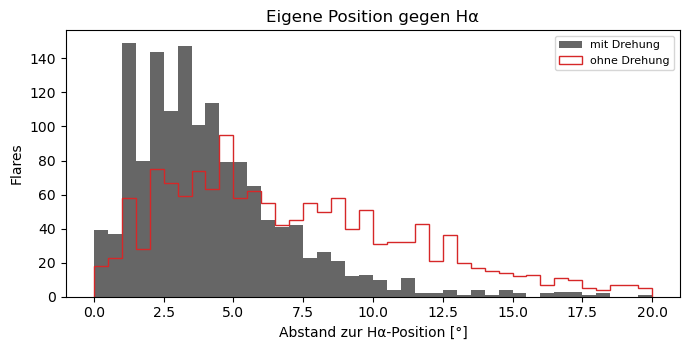

In [23]:
positions.compare(pos)

**23. Bild: der X-Flare im Blick von SDO**

Das Solar Dynamics Observatory der NASA beobachtet die Sonne seit 2010 ohne Pause, alle 12 Sekunden in zehn Wellenlängen (AIA), und misst das Magnetfeld an der Oberfläche (HMI). Geladen werden je ein Bild in 131, 171, 304 und 1600 Å und ein Magnetogramm im Maximum des X-Flares vom 3. Oktober 2024 in NOAA 13842, nahe der Scheibenmitte.

Die fünf Bilder stammen von 12:18:08 bis 12:18:30 UT. Bei einem Flare verkürzt AIA die Belichtung: in 131 Å auf 0.015 s, in 304 Å auf 0.42 s, dort ist kein Pixel gesättigt; 171 Å lief mit 2.0 s und hat 8647 gesättigte Pixel. Die Sonne erschien mit 959.1″ Radius, und ihr Nordpol war um 6.58° zur Erde geneigt.

In [24]:
PEAK = "2024-10-03T12:18:00"   # Maximum des Flares laut GOES (UT)
BOX = 200                       # Größe des Ausschnitts um die aktive Region [Bogensekunden]
img = sdo.load(PEAK, BOX)

Kanal Zeit (UT)               Belichtung    Pixel   Maximum  gesättigt
131   2024-10-03T12:18:10       0.0145 s   0.601″      4625          0
171   2024-10-03T12:18:09       1.9996 s   0.599″     16375       8647
304   2024-10-03T12:18:08       0.4158 s   0.600″     11779          0
1600  2024-10-03T12:18:14       2.9013 s   0.609″     16375         73
HMI   2024-10-03T12:18:30           45 s   0.504″      4993          -

Abstand SDO-Sonne 1.0005 AU, Sonnenradius 959.1 arcsec, B0 = 6.58 deg


**24. Die ganze Sonne in fünf Kanälen**

Jedes Bild wird auf 4 × 4 Pixel gemittelt, durch die Belichtungszeit geteilt und logarithmisch gezeigt; jeder AIA-Kanal sieht Plasma einer anderen Temperatur.

In 131 Å (heißes Plasma, etwa 10 Millionen Kelvin) ist die ruhige Sonne fast dunkel und der Flare das einzige auffällige Objekt. In 171 Å sieht man die ganze Korona mit ihren Schleifen, der Flare ist dort ein gesättigter Fleck mit Streifen. In 304 und 1600 Å leuchten der Flare und die hellen Gebiete der aktiven Regionen. Das Magnetogramm zeigt die Regionen als schwarz-weiße Paare entgegengesetzter Polarität, die meisten in einem Band südlich des Äquators.

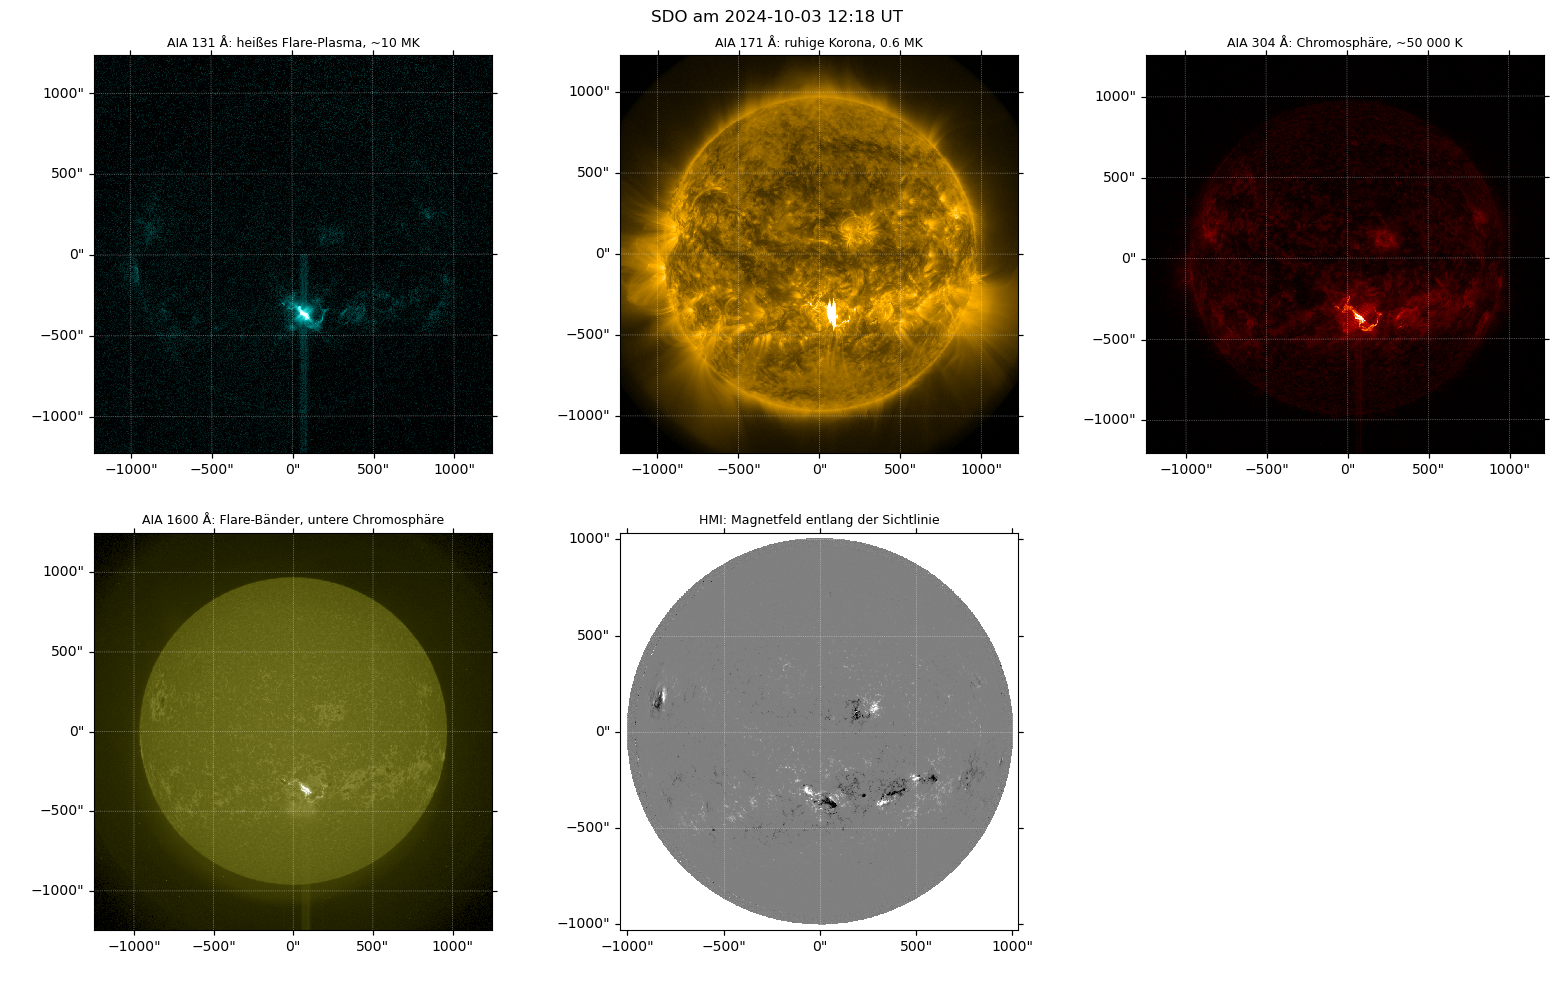

In [25]:
sdo.overview(img)

**25. Die Position des Flares**

Das 131-Å-Bild wird leicht geglättet und der hellste Punkt gesucht. Seine Bildkoordinaten werden mit einer eigenen Formel und zur Kontrolle mit sunpy in heliographische Breite und Länge umgerechnet; die Neigung der Sonnenachse geht dabei ein.

Der hellste Punkt liegt bei 84.1″, −374.6″. Die eigene Formel gibt −16.44° Breite und +5.25° Länge, also S16W05; sunpy gibt −16.34° und +5.24°, der Unterschied von 0.1° kommt von der parallelen Projektion. Ohne die Neigung von 6.6° läge die Breite um gut 6° daneben. Eine Bogensekunde entspricht an diesem Tag 725.7 km auf der Sonne.

In [26]:
sdo.locate(img)

Hellster Punkt in AIA 131 Å: Tx = 84.1″, Ty = -374.6″
Eigene Formel:  Breite -16.44°, Länge +5.25°  → S16W05,  μ = 0.916
sunpy:          Breite -16.34°, Länge +5.24°
1″ = 725.7 km auf der Sonne


**26. Die aktive Region in allen Kanälen**

Ein Ausschnitt von 200″ × 200″ um den hellsten Punkt in allen Kanälen, mit den Konturen des Magnetfelds bei ±500 Gauß (rot positiv, blau negativ).

In 131 Å leuchtet ein länglicher Bogen heißen Plasmas genau zwischen der roten und der blauen Kontur: Schleifen über der Grenze der Polaritäten. 171 Å ist um den Flare völlig übersättigt (8540 gesättigte Pixel im Ausschnitt). In 304 und 1600 Å liegen zwei helle Streifen beiderseits dieser Grenze, die Flare-Bänder. Der Flare sitzt also nicht über einem Fleck, sondern über der Umkehrlinie zwischen den Polaritäten, wie es das Standardmodell verlangt.

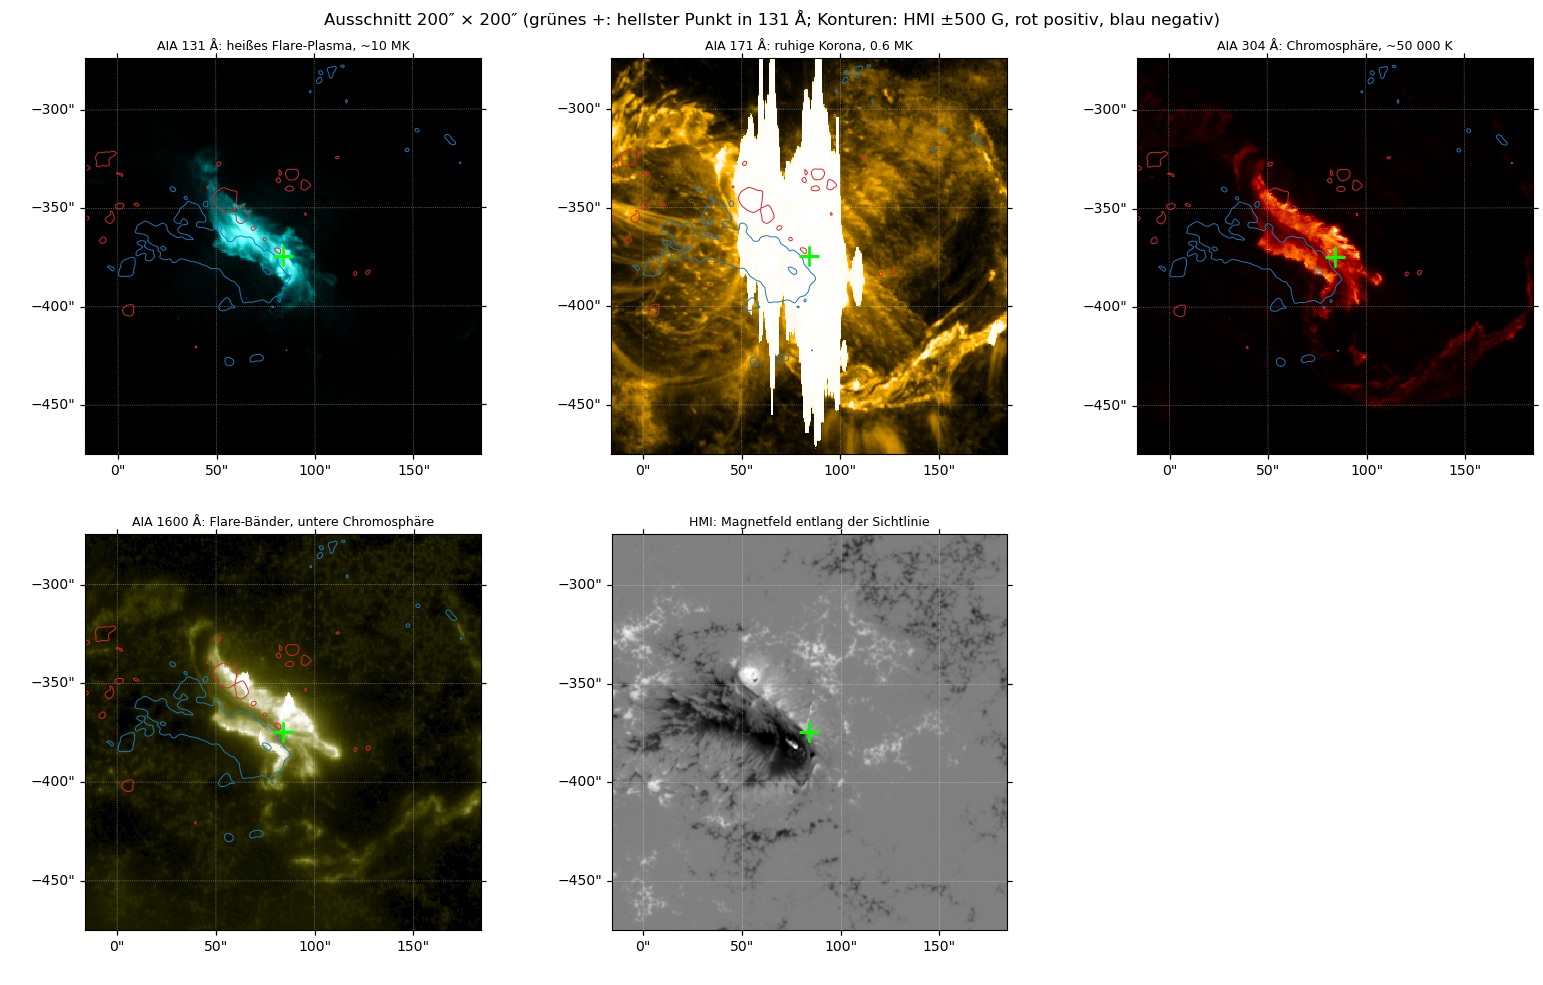

AIA 171: 8540 gesättigte Pixel im Ausschnitt
AIA 1600: 73 gesättigte Pixel im Ausschnitt


In [27]:
sdo.region(img)

**27. Magnetischer Fluss und Umkehrlinie**

Die Region ist das größte zusammenhängende Gebiet mit starkem Feld. Ihr magnetischer Fluss wird für die Schräglage zur Scheibenmitte korrigiert und nach Polarität getrennt summiert; die Umkehrlinie liegt dort, wo starkes positives und negatives Feld aneinandergrenzen.

Die Region umfasst 8000 Mm² mit 2.65·10²² Maxwell, davon 1.97·10²² negativ und nur 0.68·10²² positiv: Der große negative Fleck dominiert, seine Gegenpolarität ist schwächer und weiter verteilt. Die Umkehrlinie ist bei ±150 G etwa 30 Mm lang, bei ±500 G gibt es keine. 47 % des Flusses liegen innerhalb von 10 Mm um die Linie, und der hellste Punkt in 131 Å liegt nur 1.3 Mm von ihr entfernt.

μ im Ausschnitt 0.848 bis 0.958;  HMI-Pixel 366 km;  Rauschen ≈ 19 G
Region: 7,996 Mm²;  Φ+ = 6.79e+21 Mx,  Φ− = -1.97e+22 Mx,  |Φ| = 2.65e+22 Mx,  Ungleichgewicht (Φ+ + Φ−)/|Φ| = -0.49
Ohne μ-Korrektur wäre |Φ| = 2.26e+22 Mx
Umkehrlinie bei ±150 G: 566 Pixel, Länge ≈ 30 Mm
Umkehrlinie bei ±300 G: 113 Pixel, Länge ≈ 6 Mm
Umkehrlinie bei ±500 G: 0 Pixel, Länge ≈ 0 Mm
Anteil des Flusses der Region innerhalb von 10 Mm um die Umkehrlinie: 47%
Hellster Punkt in 131 Å: B = +382 G, 1.3 Mm von der Umkehrlinie


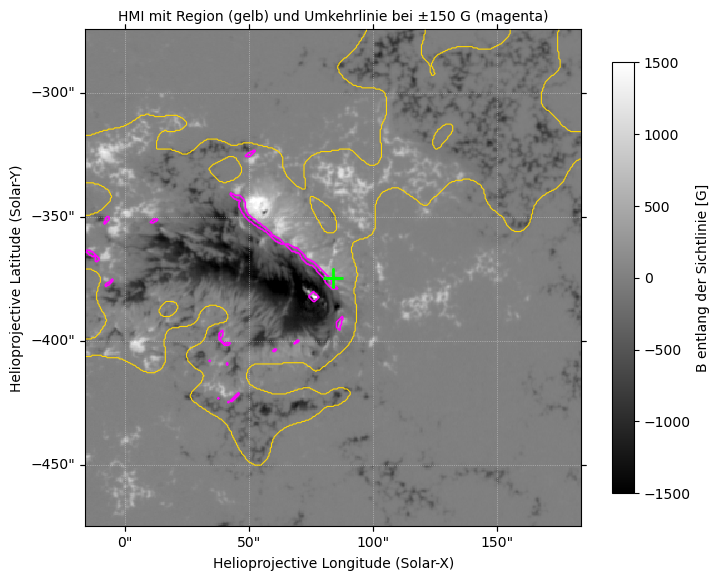

In [28]:
sdo.magnetic(img)

**28. Die Flare-Bänder und das Standardmodell**

Im Standardmodell reißen Feldlinien über der Umkehrlinie auf und verbinden sich neu (Rekonnexion); ihre Fußpunkte leuchten als zwei Bänder in entgegengesetzter Polarität, die gleich viel Fluss tragen sollten. Bandpixel sind Pixel in 1600 Å, die heller sind als das 30-Fache des Medians; ihre Orte werden ins Magnetogramm übertragen.

Zwei lange, parallele Bänder laufen beiderseits der Umkehrlinie. Das südliche liegt zu 97 % in negativer Polarität (im Mittel −950 G, 162 Mm²), das nördliche zu 69 % in positiver (+295 G, 416 Mm²). Ihr Fluss ist −1.68·10²¹ und +1.32·10²¹ Maxwell, das Verhältnis 0.79: ähnlich viel, obwohl ein Band zweieinhalbmal so groß ist, wie es das Standardmodell verlangt.

Schwelle 3630 DN (1251 DN/s), 7 zusammenhängende Gebiete
 band  pixel  flaeche_Mm2  B_mittel  anteil_pos  anteil_neg         fluss  abstand_PIL_Mm    Tx      Ty     polaritaet
    1     58        12.51     25.59        0.16        0.00  3.540296e+18            7.32 97.26 -392.52 schwaches Feld
    2    758       161.81   -950.05        0.03        0.97 -1.676974e+21            3.89 71.20 -377.93        negativ
    4   1961       416.17    295.10        0.69        0.01  1.319974e+21            5.71 80.36 -363.50        positiv

Bänder in positiver Polarität: 1, 416 Mm², Fluss +1.32e+21 Mx
Bänder in negativer Polarität: 1, 162 Mm², Fluss -1.68e+21 Mx
Verhältnis der Beträge: 0.79


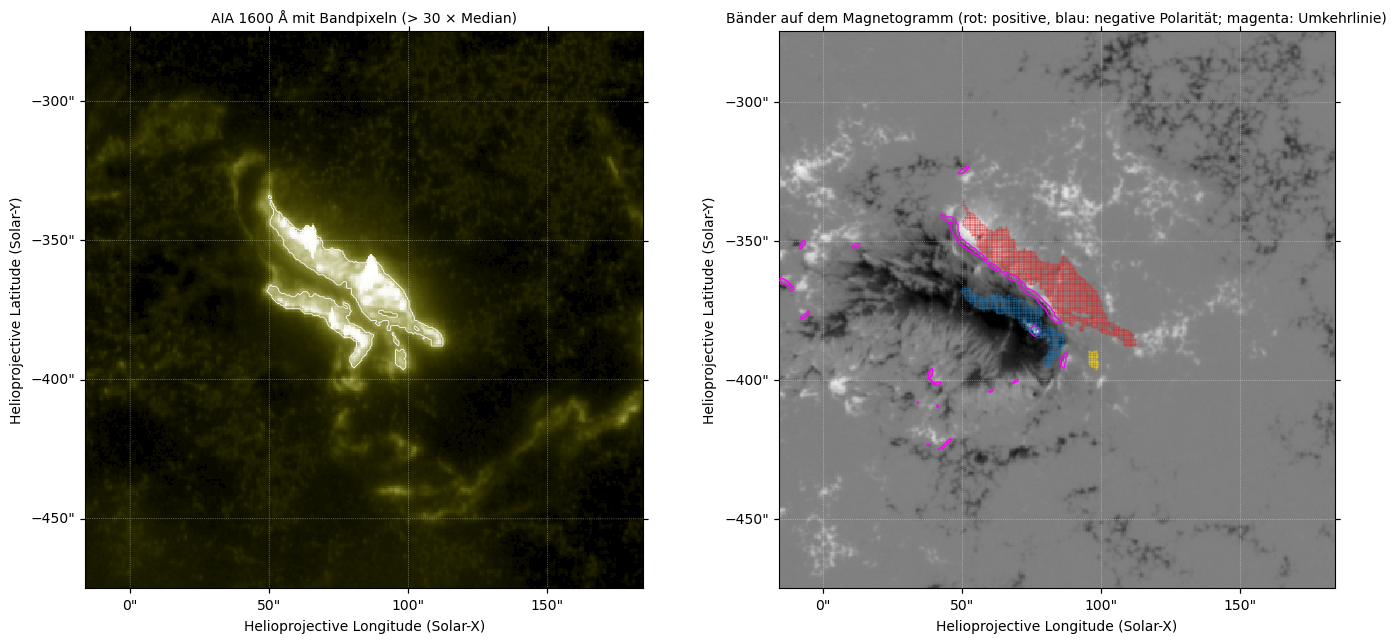

In [29]:
sdo.ribbons(img)

**29. Position im Vergleich mit HEK**

Vier Positionen des Flares nebeneinander: der Eintrag in HEK, der hellste Punkt in 131 Å, die Mitte der Bänder und der Schwerpunkt des magnetischen Flusses der Region. HEK wird mit einer Wartezeit von 30 Sekunden abgefragt; antwortet der Dienst nicht, nimmt der Code die Werte einer früheren Abfrage.

HEK antwortete und gibt 48.7″, −354.0″ (S15W03) in NOAA 13842, Klasse X9.0. Diese Position liegt 41″ (30 Mm) vom hellsten Punkt und 33″ (24 Mm) von der Mitte der Bänder entfernt, aber nur 17″ (12 Mm) vom Flussschwerpunkt der Region. Dort ist 131 Å etwa 16-mal schwächer als im Maximum und das Feld schwach (−91 G): Der Katalog beschreibt eher die Region als den Ort des Flares.

In [30]:
sdo.compare(img)

Katalog: X9.0 in NOAA 13842  (HEK, SSW Latest Events)

Position                                    Tx       Ty   heliogr.    Abstand zu HEK
HEK                                      48.7″  -354.0″   S15W03        0.0″ =    0 Mm
hellster Punkt AIA 131 Å                 84.1″  -374.6″   S16W05       41.0″ =   30 Mm
Mitte der Bänder AIA 1600 Å              78.2″  -368.0″   S16W05       32.7″ =   24 Mm
Flussschwerpunkt der Region (HMI)        65.0″  -358.5″   S15W04       17.0″ =   12 Mm

An der HEK-Position: B = -91 G, 2.1 Mm von der Umkehrlinie, AIA 131 Å 294 DN (Maximum im Ausschnitt 4625 DN)
